# Loading the PDF

In [27]:
from langchain_community.document_loaders import PyPDFLoader

In [28]:
pdf_path = r"C:\Users\balaj\OneDrive\Desktop\Embedded-System-Assistant RAG\embedded-systems.pdf".replace("\\", "/")
loader = PyPDFLoader(pdf_path)
pdf = loader.load()

In [29]:
print(f"PDF Length: {len(pdf)}", end="\n\n")
print(f'First Page Content: {pdf[0].page_content[:200]}')  # Print first 500 characters of the first page

PDF Length: 209

First Page Content: Embedded Systems Design: An Introduction to Processes, Tools, and 
Techniques 
by Arnold S. Berger ISBN: 1578200733 
CMP Books © 2002 (237 pages) 
An easy-to-understand guidebook for those embarking u


# Extracting Youtube Video Text using Parser

In [30]:
from langchain_community.document_loaders.generic import GenericLoader # to load any type of document
from langchain_community.document_loaders.blob_loaders.youtube_audio import YoutubeAudioLoader # to load audio from YouTube
from langchain_community.document_loaders.parsers.audio import FasterWhisperParser # to parse audio files using Faster Whisper

In [31]:
url = "https://www.youtube.com/watch?v=uFhDGagZzjs"
save_dir = r"C:\Users\balaj\OneDrive\Desktop\Embedded-System-Assistant RAG"

# os.makedirs(save_dir, exist_ok=True)

loader = GenericLoader(
    YoutubeAudioLoader([url], save_dir),
    FasterWhisperParser()
)

youtube_audio = loader.load()

print(f"Loaded {len(youtube_audio)} document(s)")
print(youtube_audio[0].page_content[:500])

[youtube] Extracting URL: https://www.youtube.com/watch?v=uFhDGagZzjs
[youtube] uFhDGagZzjs: Downloading webpage
[youtube] uFhDGagZzjs: Downloading visionos player API JSON
[youtube] uFhDGagZzjs: Downloading m3u8 information
[info] uFhDGagZzjs: Downloading 1 format(s): 140-5
[download] C:\Users\balaj\OneDrive\Desktop\Embedded-System-Assistant RAG\Lecture 01： Introduction to Embedded Systems.m4a has already been downloaded
[download] 100% of   27.27MiB
[ExtractAudio] Not converting audio C:\Users\balaj\OneDrive\Desktop\Embedded-System-Assistant RAG\Lecture 01： Introduction to Embedded Systems.m4a; file is already in target format m4a
Loaded 219 document(s)
 Let me welcome you to this course which will be conducted jointly by myself and Doctor


In [32]:
print(f"Loaded {len(youtube_audio)} document(s)")
print(youtube_audio[0].page_content[:500])

Loaded 219 document(s)
 Let me welcome you to this course which will be conducted jointly by myself and Doctor


In [33]:
combined_docs = pdf + youtube_audio
print(f'''Combined Docs Length: {len(combined_docs)}''')

Combined Docs Length: 428


# Chunking

In [34]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [35]:
chunk_size = 1024
chunk_overlap = 200

In [36]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=chunk_size,
    chunk_overlap=chunk_overlap,
)

In [37]:
chunked_docs = splitter.split_documents(combined_docs)

In [38]:
chunked_docs[0]

Document(metadata={'producer': 'Acrobat Distiller 4.0 for Windows', 'creator': 'PyPDF', 'creationdate': '1999-05-17T00:46:04+00:00', 'moddate': '2004-07-22T18:57:31+03:00', 'source': 'C:/Users/balaj/OneDrive/Desktop/Embedded-System-Assistant RAG/embedded-systems.pdf', 'total_pages': 209, 'page': 0, 'page_label': '1'}, page_content='Embedded Systems Design: An Introduction to Processes, Tools, and \nTechniques \nby Arnold S. Berger ISBN: 1578200733 \nCMP Books © 2002 (237 pages) \nAn easy-to-understand guidebook for those embarking upon an embedded \nprocessor development project.  \n \n \nTable of Contents  \n \n \nEmbedded Systems Design—An Introduc tion to Processes, Tools, and \nTechniques  \n Preface  \n Introduction  \n Chapter 1 - The Embedded Design Life Cycle \n Chapter 2 - The Selection Process \n Chapter 3 - The Partitioning Decision \n Chapter 4 - The Development Environment \n Chapter 5 - Special Software Techniques \n Chapter 6 - A Basic Toolset \n Chapter 7 - BDM, JTAG, a

In [39]:
len(chunked_docs)

897

# Embedding

### Embedding Model setup

In [7]:
import os
from dotenv import load_dotenv
from langchain_google_genai import GoogleGenerativeAIEmbeddings

In [13]:
load_dotenv()

True

In [14]:
api_key = os.getenv("GEMINI_API_KEY")

In [15]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001",
    google_api_key=api_key, 
    output_dimensionality=768
)

### Embedding Example

In [16]:
sen1 = "I like Machine Learning"
sen2 = "I love Aritificial Intelligence"
sen3 = "Today is a bad day"

In [18]:
es1 = embeddings.embed_query(sen1)
es2 = embeddings.embed_query(sen2)
es3 = embeddings.embed_query(sen3)

In [20]:
print(f'Sample Embeddings: {es1[:5]}')
print(f'Length of Embeddings: {len(es1)}')

Sample Embeddings: [-0.012686148, 0.0066322447, 0.008578256, -0.09411383, 0.003064384]
Length of Embeddings: 768


### Cosine Similarity

In [22]:
import numpy as np
print('Sen1: ', sen1)
print('Sen2: ', sen2)
print('Sen3: ', sen3, end="\n\n")
print(f'Cosine Similarity between sen1 and sen2: {np.dot(es1, es2) / (np.linalg.norm(es1) * np.linalg.norm(es2))}')
print(f'Cosine Similarity between sen1 and sen3: {np.dot(es1, es3) / (np.linalg.norm(es1) * np.linalg.norm(es3))}')
print(f'Cosine Similarity between sen2 and sen3: {np.dot(es2, es3) / (np.linalg.norm(es2) * np.linalg.norm(es3))}')

Sen1:  I like Machine Learning
Sen2:  I love Aritificial Intelligence
Sen3:  Today is a bad day

Cosine Similarity between sen1 and sen2: 0.7888035524955398
Cosine Similarity between sen1 and sen3: 0.516946569815661
Cosine Similarity between sen2 and sen3: 0.47981032723415334


In [41]:
from langchain_community.embeddings import HuggingFaceEmbeddings

In [42]:
loc_embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

# Vector DB 

In [23]:
!pip install chromadb --quiet

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
botocore 1.43.125 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 4.0.0 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
from langchain_community.vectorstores import Chroma

In [25]:
db_dir = r"C:\Users\balaj\OneDrive\Desktop\Embedded-System-Assistant RAG\chroma_db"

In [ ]:
vectordb = Chroma.from_documents(
    documents=chunked_docs
    embedding=loc_embeddings,
    persist_directory=db_dir
)

### Asking a Question in Vector DB 

In [45]:
question = "What is an embedded system?"

In [47]:
vectordb.similarity_search(question, k=5)

[Document(metadata={'language': 'en', 'probability': '96%', 'timestamps': '[78.40s -> 85.92s]', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a'}, page_content='an embedded system. What are the main characteristics of an embedded system and what are the design'),
 Document(metadata={'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a', 'probability': '96%', 'timestamps': '[469.36s -> 477.60s]', 'language': 'en'}, page_content='Now talking about this embedded systems again what are these embedded systems? I already'),
 Document(metadata={'language': 'en', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a', 'timestamps': '[95.20s -> 106.80s]', 'probability': '96%'}, page_content='Embedded Systems. Here we shall be primarily talking about embedded systems wha

In [51]:
vectordb.similarity_search_with_score(question, k=5)

[(Document(metadata={'language': 'en', 'probability': '96%', 'timestamps': '[78.40s -> 85.92s]', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a'}, page_content='an embedded system. What are the main characteristics of an embedded system and what are the design'),
  0.3316214084625244),
 (Document(metadata={'language': 'en', 'probability': '96%', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a', 'timestamps': '[469.36s -> 477.60s]'}, page_content='Now talking about this embedded systems again what are these embedded systems? I already'),
  0.35451292991638184),
 (Document(metadata={'language': 'en', 'timestamps': '[95.20s -> 106.80s]', 'probability': '96%', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a'}, page_content='Embedded Systems. Here we sha

### Marginal Search Retrival

In [ ]:
vectordb.max_marginal_relevance_search(question, k=5, fetch_k=10) # it returns the most relevant documents while ensuring diversity among the results. It fetches the top `fetch_k` documents based on similarity and then selects `k` documents that are both relevant and diverse.

[Document(metadata={'timestamps': '[78.40s -> 85.92s]', 'language': 'en', 'probability': '96%', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a'}, page_content='an embedded system. What are the main characteristics of an embedded system and what are the design'),
 Document(metadata={'language': 'en', 'timestamps': '[1473.28s -> 1480.32s]', 'probability': '96%', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a'}, page_content='like AC machine like microwave like refrigerator and so on this is what an embedded system is'),
 Document(metadata={'probability': '96%', 'language': 'en', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a', 'timestamps': '[1458.88s -> 1464.96s]'}, page_content='traditional computing system no it is not we call it a computer we do

### MetaData Filtering

In [58]:
vectordb.similarity_search(question, k=5, filter={'source':pdf_path})

[Document(metadata={'page_label': '8', 'source': 'C:/Users/balaj/OneDrive/Desktop/Embedded-System-Assistant RAG/embedded-systems.pdf', 'creator': 'PyPDF', 'total_pages': 209, 'creationdate': '1999-05-17T00:46:04+00:00', 'moddate': '2004-07-22T18:57:31+03:00', 'page': 7, 'producer': 'Acrobat Distiller 4.0 for Windows'}, page_content='desktop PC and the typical embedded system. \n \n\x83 Embedded systems are dedicated to specific tasks, whereas PCs are \ngeneric computing platforms. \n\x83 Embedded systems are supported by a wide array of processors and \nprocessor architectures. \n\x83 Embedded systems are usually cost sensitive. \n\x83 Embedded systems have real-time constraints.'),
 Document(metadata={'total_pages': 209, 'page_label': '100', 'page': 99, 'creator': 'PyPDF', 'moddate': '2004-07-22T18:57:31+03:00', 'producer': 'Acrobat Distiller 4.0 for Windows', 'source': 'C:/Users/balaj/OneDrive/Desktop/Embedded-System-Assistant RAG/embedded-systems.pdf', 'creationdate': '1999-05-17T00

In [59]:
print(f'PDF Directory: {pdf_path}')

PDF Directory: C:/Users/balaj/OneDrive/Desktop/Embedded-System-Assistant RAG/embedded-systems.pdf


# Response Generation

In [61]:
!pip install langchain-groq --quiet


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [68]:
load_dotenv()

True

In [69]:
groq_api = os.getenv("GROQ_API_KEY")

In [66]:
from langchain_groq import ChatGroq

In [79]:
llm = ChatGroq(
    model="qwen/qwen3.8-27b",
    groq_api_key=groq_api, 
    temperature=0.2,
    max_tokens=300
)

In [81]:
res = llm.invoke("Write a python code to find the factorial of a number")

In [83]:
print(res.content)

# Factorial of a Number in Python

Here are several ways to find the factorial of a number in Python:

## Method 1: Using a Loop

```python
def factorial_loop(n):
    """Calculate factorial using a loop."""
    if n < 0:
        raise ValueError("Factorial is not defined for negative numbers")
    if n == 0 or n == 1:
        return 1
    
    result = 1
    for i in range(2, n + 1):
        result *= i
    return result

# Example usage
number = 5
print(f"Factorial of {number} is: {factorial_loop(number)}")
```

## Method 2: Using Recursion

```python
def factorial_recursive(n):
    """Calculate factorial using recursion."""
    if n < 0:
        raise ValueError("Factorial is not defined for negative numbers")
    if n == 0 or n == 1:
        return 1
    return n * factorial_recursive(n - 1)

# Example usage
number = 5
print(f"Factorial of {number} is: {factorial_recursive(number)}")
```

## Method 3: Using `math.factorial` (Built-in)

```python
import math

number = 5
print(f"Facto

### Prompt Engineering 

In [ ]:
system_prompt = (
    "You are an assistant for question-answering tasks. Use the following pieces of retrieved context to answer the question."
    "If you don't know the answer, just say that you don't know. Use three sentences maximum and keep the answer concise."
    "Answer all questions to the best of your ability."
    )

# we can use langchain hub for finding prompts as well. For example, we can use the prompt below for question answering tasks.  

In [85]:
from langchain.messages import HumanMessage, AIMessage, SystemMessage

In [108]:
system_msg = [SystemMessage(content=system_prompt)]

In [86]:
docs = vectordb.similarity_search_with_score(question, k=5)

In [87]:
import pandas as pd

_docs = pd. DataFrame(
    [(question, doc[0].page_content, doc[0].metadata.get('source'), doc[0].metadata.get('page'), doc[1]) for doc in docs],
    columns=['query', 'paragraph', 'document', 'page_number', 'relevant_score']
    )

In [88]:
_docs

,query,paragraph,document,page_number,relevant_score
0,What is an embedded system?,an embedded system. What are the main characte...,C:\Users\balaj\OneDrive\Desktop\Embedded-Syste...,None,0.331621
1,What is an embedded system?,Now talking about this embedded systems again ...,C:\Users\balaj\OneDrive\Desktop\Embedded-Syste...,None,0.354513
2,What is an embedded system?,Embedded Systems. Here we shall be primarily t...,C:\Users\balaj\OneDrive\Desktop\Embedded-Syste...,None,0.388467
3,What is an embedded system?,talked about so far. Well embedded system can ...,C:\Users\balaj\OneDrive\Desktop\Embedded-Syste...,None,0.402218
4,What is an embedded system?,environment for which they were created. Now s...,C:\Users\balaj\OneDrive\Desktop\Embedded-Syste...,None,0.456549


In [96]:
docs

[(Document(metadata={'timestamps': '[78.40s -> 85.92s]', 'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a', 'language': 'en', 'probability': '96%'}, page_content='an embedded system. What are the main characteristics of an embedded system and what are the design'),
  0.3316214084625244),
 (Document(metadata={'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a', 'probability': '96%', 'timestamps': '[469.36s -> 477.60s]', 'language': 'en'}, page_content='Now talking about this embedded systems again what are these embedded systems? I already'),
  0.35451292991638184),
 (Document(metadata={'source': 'C:\\Users\\balaj\\OneDrive\\Desktop\\Embedded-System-Assistant RAG\\Lecture 01： Introduction to Embedded Systems.m4a', 'timestamps': '[95.20s -> 106.80s]', 'probability': '96%', 'language': 'en'}, page_content='Embedded Systems. Here we sha

In [102]:
context = "\n\n".join(_docs['paragraph'])
context 

'an embedded system. What are the main characteristics of an embedded system and what are the design\n\nNow talking about this embedded systems again what are these embedded systems? I already\n\nEmbedded Systems. Here we shall be primarily talking about embedded systems what it is basically\n\ntalked about so far. Well embedded system can be loosely defined as a microcontroller based\n\nenvironment for which they were created. Now such systems are traditionally referred to as embedded'

In [107]:
human_msg = [HumanMessage(content = question+context)]

In [109]:
response = llm.invoke(system_msg + human_msg)

In [110]:
response.content

'An embedded system is a microcontroller-based environment designed to perform specific functions within a larger mechanical or electrical system. Its main characteristics include being dedicated to a particular task, operating with real-time constraints, and often having limited computational resources. Design considerations typically focus on optimizing for cost, power consumption, and reliability while meeting strict performance requirements.'

In [111]:
from langgraph. checkpoint.memory import MemorySaver
from langgraph.graph import START, MessagesState, StateGraph

workflow = StateGraph(state_schema=MessagesState)

# Define the function that calls the model
def call_model(state: MessagesState):
    system_prompt =(
    "You are a helpful assistant. "
    "Answer all questions to the best of your ability." 
    )
    messages = [SystemMessage(content=system_prompt)] + state["messages"]
    response = llm.invoke(messages)
    return {"messages": response}

# Define the node and edge
workflow.add_node("model", call_model)
workflow. add_edge(START, "model")

# Add simple in-memory checkpointer
memory = MemorySaver()
app = workflow.compile(checkpointer=memory) 

This code creates a **simple conversational AI agent using LangGraph**. It sends the user’s conversation to an LLM, gets a response, and remembers prior messages in memory so the chat can continue with context.

```python
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import START, MessagesState, StateGraph
```

- `MemorySaver`: stores conversation state in your program’s RAM. It is useful for testing, but the chat history disappears when the program stops.
- `START`: marks where the graph begins.
- `MessagesState`: a built-in state format designed for chat messages.
- `StateGraph`: lets you define a workflow as nodes and connections.

## Create the graph

```python
workflow = StateGraph(state_schema=MessagesState)
```

This creates a LangGraph workflow whose state is a list of chat messages. `MessagesState` normally contains a key called `messages`, which holds the conversation history.

## Define the model node

```python
def call_model(state: MessagesState):
```

This function is a **node** in the graph. LangGraph calls it with the current conversation state.

```python
system_prompt = (
    "You are a helpful assistant. "
    "Answer all questions to the best of your ability."
)
```

This sets the assistant’s basic behavior: helpful and general-purpose.

```python
messages = [SystemMessage(content=system_prompt)] + state["messages"]
```

It builds the full message list sent to the model:

1. The system instruction.
2. All previous user and AI messages.
3. The newest user message, which is already part of `state["messages"]`.

For example, if the user previously asked, “What is an embedded system?” and now asks, “Give an example,” the model receives both messages and can understand that “an example” refers to embedded systems.

```python
response = llm.invoke(messages)
return {"messages": response}
```

This calls your configured LLM—for example, an OpenAI, Anthropic, Groq, or Ollama model—and returns its response. LangGraph merges that response into the conversation state.

**Important:** in many LangGraph versions, return the response wrapped in a list:

```python
return {"messages": [response]}
```

`MessagesState` has an add-messages reducer, so returning `[response]` appends the AI response to the existing history rather than replacing it.

## Build the graph

```python
workflow.add_node("model", call_model)
workflow.add_edge(START, "model")
```

- `add_node("model", call_model)` registers your LLM-calling function as a node named `"model"`.
- `add_edge(START, "model")` says: when the graph starts, go directly to the `model` node.

There is no edge from `model` back to `START` or to another node, so this is a one-step graph: receive messages, call the model, return the updated messages.

## Add memory

```python
memory = MemorySaver()
app = workflow.compile(checkpointer=memory)
```

- `MemorySaver()` creates an in-memory checkpoint store.
- `workflow.compile(checkpointer=memory)` turns the graph into a runnable application.
- The checkpointer saves the state after each graph step.

This is what allows multi-turn chat: when you invoke the app again with the same `thread_id`, it can retrieve the prior messages and send the whole conversation to the model.

## How you would use it

```python
config = {"configurable": {"thread_id": "user-1"}}

result = app.invoke(
    {"messages": [("user", "What is an embedded system?")]},
    config
)

print(result["messages"][-1].content)
```

Then ask a follow-up using the **same** `thread_id`:

```python
result = app.invoke(
    {"messages": [("user", "Give one example.")]},
    config
)
```

Because both calls use `thread_id: "user-1"`, the second request includes the earlier question and answer.

## Small corrections

Your pasted code has two likely formatting issues:

```python
from langgraph. checkpoint.memory import MemorySaver
```

should be:

```python
from langgraph.checkpoint.memory import MemorySaver
```

And:

```python
workflow. add_edge(START, "model")
```

should be:

```python
workflow.add_edge(START, "model")
```

Also ensure `SystemMessage` is imported:

```python
from langchain_core.messages import SystemMessage
```

And that `llm` is defined before `call_model` runs, for example:

```python
llm = ChatOpenAI(model="gpt-4o-mini")
```

## In one sentence

This code builds a stateful chatbot graph: it takes the user’s message, adds a system prompt and prior history, calls the LLM, saves the updated conversation in memory, and can continue the same conversation later using a thread ID.

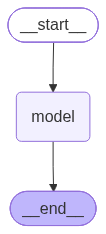

In [112]:
app